In [1]:
import numpy as np
import xarray as xr
from scipy.sparse.linalg import svds
from matplotlib import pyplot as plt
import seaborn as sns
import fastplotlib as fpl
from tqdm import tqdm
from ipywidgets import interact
from collections import OrderedDict
from pathlib import Path
from itertools import product
from scipy.linalg import svd
from tslearn.metrics.cycc import normalized_cc

using: <jupyter_rfb._jpg.SimpleJpegEncoder object at 0x7f70d5a49150>


Parameters:
* Noise
* Length of recording
* length of single transient
* n_steps
* delay

`DataArray` for each:
* `TdSVD` objects
* normalized `S_0 - S_1` for just `TdSVD`
* normalized `td_S1 - svd_S1`
* normalized cross correlation tdsvd and svd
* max(n_cc) tdsvd and svd

In [26]:
coords = OrderedDict([
    ("noise", np.array([1, 3, 7])), # noise sigma
    ("rlen", np.array([10_000])), # recording length
    ("tlen", np.array([25, 100, 150])), # transient length
    ("n_steps", np.array([15, 25, 50, 100, 125, 150])), # n time steps
    ("delay", np.array([1])), # delay
])

In [27]:
coords

OrderedDict([('noise', array([1, 3, 7])),
             ('rlen', array([10000])),
             ('tlen', array([ 25, 100, 150])),
             ('n_steps', array([ 15,  25,  50, 100, 125, 150])),
             ('delay', array([1]))])

In [28]:
n_samples = 10

In [29]:
data_array_names = ["tdsvd", "s_gap_td", "s_gap_svd", "ncc_td", "ncc_svd"]
data_arrays = dict()
data_arrays_samples = list()

for i in range(n_samples):
    for n in data_array_names:
        _data = np.empty(shape=tuple(len(coords[k]) for k in coords.keys()), dtype=object)
        data_arrays[n] = xr.DataArray(
            _data, 
            coords=coords,
        )
    data_arrays_samples.append(data_arrays)

In [30]:
a = data_arrays["tdsvd"]
a[a["noise"] == 1, a["rlen"] == 1000, a["tlen"] == 3, a["n_steps"] == 5, a["delay"] == 3]

<xarray.DataArray (noise: 1, rlen: 0, tlen: 0, n_steps: 0, delay: 0)>
array([], shape=(1, 0, 0, 0, 0), dtype=object)
Coordinates:
  * noise    (noise) int64 1
  * rlen     (rlen) int64 
  * tlen     (tlen) int64 
  * n_steps  (n_steps) int64 
  * delay    (delay) int64

In [31]:
coords["noise"]

array([1, 3, 7])

# Add multiple toy data samples and average over runs

In [32]:
toy_samples = list()
toy_samples_clean = list()

for sample_i in range(n_samples):
    toy_datasets = dict()
    toy_datasets_clean = dict()
    for noise in coords["noise"]:
        _inner_dict = dict()
        _inner_dict_clean = dict()
        
        for tlen in coords["tlen"]:
            toy_shape = (2, 10_000)
            p1 = 0.01
            pixels = np.random.choice(a=[0, 1], size=toy_shape, p=[1-p1, p1])
            pixels[1:] = pixels[0]
            
            pixels[pixels == 2] = 1
            
            for i in range(pixels.shape[0]):
                for j in range(tlen):
                    pixels[i] += np.roll(pixels[i], shift=1)
            
            pixels[pixels > 1] = 1
            pixels = pixels.astype(float)
            
            pixels_clean = pixels.copy()
            
            # for i in range(pixels.shape[0]):
            #     pixels[i] += np.random.normal(0, noise, size=toy_shape[1])
                
            _inner_dict[tlen] = pixels
            _inner_dict_clean[tlen] = pixels_clean
        
        toy_datasets[noise] = _inner_dict
        toy_datasets_clean[noise] = _inner_dict_clean

    toy_samples.append(toy_datasets)
    toy_samples_clean.append(toy_datasets_clean)

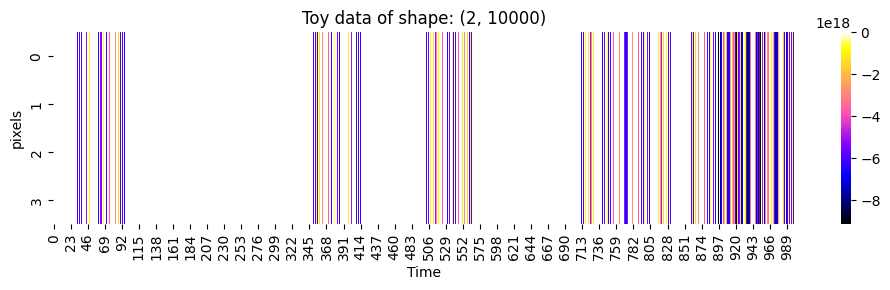

In [33]:
fig = plt.figure(figsize=(10, 3))
noise_index = 2
sns.heatmap(
    np.vstack(
        [
            toy_datasets_clean[coords["noise"][noise_index]][coords["tlen"][1]], 
            toy_datasets[coords["noise"][noise_index]][coords["tlen"][1]]
        ]
    )[:, :1000], 
    cmap="gnuplot2"
)
plt.title(f"Toy data of shape: {toy_shape}")
plt.xlabel("Time")
plt.ylabel("pixels"), pixels
plt.tight_layout()
plt.show()

In [10]:
class TdSVD:
    @staticmethod
    def create_embedding(data: np.ndarray, n_time_steps: int, delay: int, filename: str):
        n_timepoints = data.shape[1]
        n_pixels = data.shape[0]
        
        A = np.zeros((n_pixels * n_time_steps, n_timepoints - (n_time_steps * delay)), dtype=np.float32)
        
        for pixel_ix in range(n_pixels):
            for step in range(n_time_steps):
                A[(n_time_steps * pixel_ix) + step] = np.roll(data[pixel_ix], shift=-delay * step)[:-n_time_steps * delay]
        return A
        
    def __init__(
        self,
        data: np.ndarray,
        filename_embedding: str,
        n_time_steps: int,
        delay: int,
    ):
        self.n_time_steps = n_time_steps
        
        n_timepoints = data.shape[1]
        self.n_pixels = data.shape[0]

        self.A = self.create_embedding(data, n_time_steps, delay, filename_embedding)

        self.k, self.U, self.S, self.V = None, None, None, None
    
    def fit(self, k=6, **kwargs):
        self.k = k
        U, S, V = svds(self.A, k=self.k, **kwargs)
        self.U = U[:, ::-1]
        self.S = S[::-1]
        self.V = V[::-1, :]

    def get_spatial(self):
        return self.U.reshape(self.n_pixels, self.n_time_steps, self.k)

In [11]:
def product_dict(kwargs):
    keys = kwargs.keys()
    for instance in product(*kwargs.values()):
        yield OrderedDict(zip(keys, instance))

In [12]:
len(list(product_dict(coords)))

240

In [13]:
for i, params in enumerate(list(product_dict(coords))):
    print(params)
    if i > 1:
        break

OrderedDict([('noise', 1), ('rlen', 10000), ('tlen', 25), ('n_steps', 15), ('delay', 1)])
OrderedDict([('noise', 1), ('rlen', 10000), ('tlen', 25), ('n_steps', 15), ('delay', 5)])
OrderedDict([('noise', 1), ('rlen', 10000), ('tlen', 25), ('n_steps', 25), ('delay', 1)])


In [14]:
for params in tqdm(list(product_dict(coords))):
    for sample_i in range(n_samples):
        data = toy_samples[sample_i][params["noise"]][params["tlen"]][:, :params["rlen"]]
        data_clean = toy_samples_clean[sample_i][params["noise"]][params["tlen"]][:, :params["rlen"]]
        fname = "_".join(f"{k}-{v}" for k, v in params.items())
    
        # check for negative embedding dimensions
        if params["rlen"] - (params["n_steps"] * params["delay"]) < 1:
            continue
    
        tdsvd = TdSVD(
            data=data,
            filename_embedding=fname,
            n_time_steps=params["n_steps"],
            delay=params["delay"]
        )
        
        tdsvd.fit(k=2)
        
        snorm_td = tdsvd.S / tdsvd.S.max()
        s_gap_td = snorm_td[0] - snorm_td[1]
    
        u, s, v = svd(pixels.astype(float))
        
        snorm = s / s.max()
        s_gap_svd = snorm[0] - snorm[1]
    
        for name, val in zip(["tdsvd", "s_gap_td", "s_gap_svd"], [tdsvd, s_gap_td, s_gap_svd]):
            a = data_arrays_samples[i][name]
            a[
                a["noise"] == params["noise"], 
                a["rlen"] == params["rlen"], 
                a["tlen"] == params["tlen"], 
                a["n_steps"] == params["n_steps"], 
                a["delay"] == params["delay"]
            ] = np.array(val)

100%|█████████████████████████████████████████████████████████████████████████████████| 240/240 [13:09<00:00,  3.29s/it]


In [19]:
data_arrays_samples[0]["s_gap_td"]

<xarray.DataArray (noise: 3, rlen: 1, tlen: 5, n_steps: 8, delay: 2)>
array([[[[[0.6595267057418823, 0.3071480393409729],
          [0.533495306968689, 0.3660160303115845],
          [0.47432219982147217, 0.4015665650367737],
          [0.3400194048881531, 0.49482911825180054],
          [0.3093661665916443, 0.5694277286529541],
          [0.3329905867576599, 0.6069389581680298],
          [0.36765873432159424, 0.6316132545471191],
          [0.4030718207359314, 0.6523512005805969]],

         [[0.7799121141433716, 0.4751436114311218],
          [0.7124103307723999, 0.4273935556411743],
          [0.6828961968421936, 0.4429423213005066],
          [0.5770317316055298, 0.5290142297744751],
          [0.4763150215148926, 0.5840981006622314],
          [0.4330880045890808, 0.6172909736633301],
          [0.42815518379211426, 0.6328767538070679],
          [0.44345623254776, 0.6408507227897644]],

         [[0.25815945863723755, 0.38708484172821045],
          [0.1620579957962036, 0.36152803897857666],
...
          [0.2584204077720642, 0.08398395776748657],
          [0.17949002981185913, 0.26588213443756104]],

         [[0.17032212018966675, 0.3749217987060547],
          [0.3109745979309082, 0.08459270000457764],
          [0.10412520170211792, 0.19313794374465942],
          [0.47798651456832886, 0.18974655866622925],
          [0.24056768417358398, 0.12964171171188354],
          [0.15005528926849365, 0.21067196130752563],
          [0.09329181909561157, 0.2302904725074768],
          [0.1675240397453308, 0.034208595752716064]],

         [[0.3776776194572449, 0.34104132652282715],
          [0.4104498624801636, 0.28940677642822266],
          [0.2543008327484131, 0.34530186653137207],
          [0.42656683921813965, 0.06490975618362427],
          [0.18754225969314575, 0.24294418096542358],
          [0.09084063768386841, 0.1086074709892273],
          [0.049176692962646484, 0.3515462875366211],
          [0.13243907690048218, 0.233597993850708]]]]], dtype=object)
Coordinates:
  * noise    (noise) int64 1 3 7
  * rlen     (rlen) int64 10000
  * tlen     (tlen) int64 25 50 75 100 125
  * n_steps  (n_steps) int64 15 25 30 50 75 100 125 150
  * delay    (delay) int64 1 5

<Axes: xlabel='None-n_steps', ylabel='noise'>

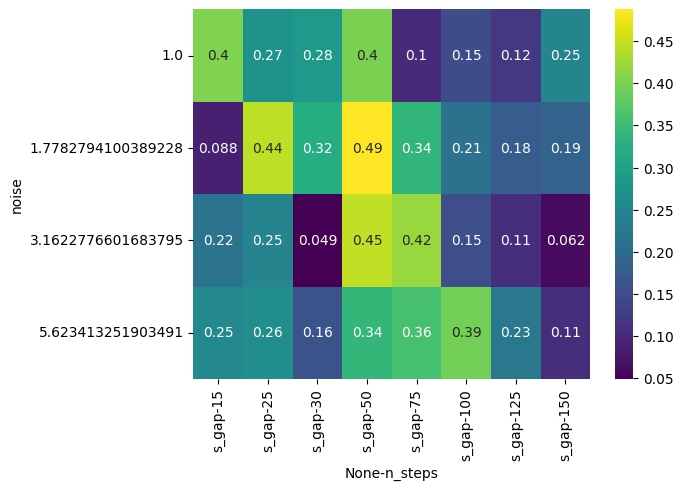

In [15]:
a = data_arrays["s_gap_td"]
sel = a[:, a["rlen"] == 10_000, a["tlen"] == 75, :, a["delay"] == 1]
df = sel.squeeze().astype(float).to_dataframe(name="s_gap").drop(columns=["rlen", "tlen", "delay"]).unstack()
sns.heatmap(df, annot=True, cmap="viridis")

In [146]:
a = data_arrays["tdsvd"]
sel = a[a["noise"] == 1.0, a["rlen"] == 10_000, a["tlen"] == 10, :, a["delay"] == 1]

In [147]:
sel = sel.squeeze()
sel

<xarray.DataArray (n_steps: 4)>
array([<__main__.TdSVD object at 0x7f5602830ad0>,
       <__main__.TdSVD object at 0x7f54bc637c90>,
       <__main__.TdSVD object at 0x7f54be7d73d0>,
       <__main__.TdSVD object at 0x7f54be7ced10>], dtype=object)
Coordinates:
    noise    float64 1.0
    rlen     int64 10000
    tlen     int64 10
  * n_steps  (n_steps) int64 3 10 25 50
    delay    int64 1

3: [1.         0.80588883]
10: [1.         0.72676355]
25: [1.        0.8058282]
50: [1.        0.7715512]


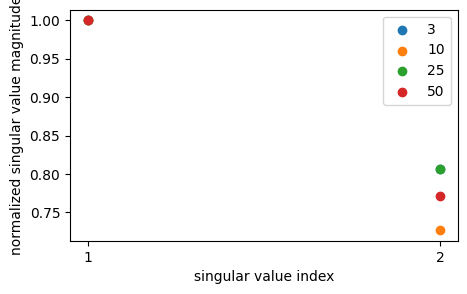

In [148]:
fig = plt.figure(figsize=(5, 3))

for n in [3, 10, 25, 50]:
    S = sel[sel.n_steps == n].item().S
    vals = S / S.max()
    plt.scatter(x=[1, 2], y=vals, label=n)
    print(f"{n}: {vals}")
    
plt.legend()
plt.xlabel("singular value index")
plt.xticks([1, 2], [1, 2])
plt.ylabel("normalized singular value magnitude")
plt.show()

In [149]:
S = sel[sel.n_steps == 10].item()

<Axes: xlabel='None-n_steps', ylabel='noise'>

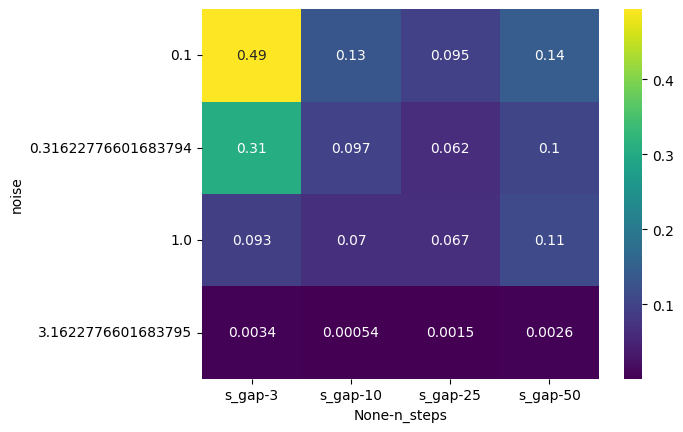

In [150]:
a = data_arrays["s_gap_td"]
sel = a[:, a["rlen"] == 10_000, a["tlen"] == 3, :, a["delay"] == 1]
df = sel.squeeze().astype(float).to_dataframe(name="s_gap").drop(columns=["rlen", "tlen", "delay"]).unstack()
sns.heatmap(df, annot=True, cmap="viridis")

<Axes: xlabel='None-n_steps', ylabel='noise'>

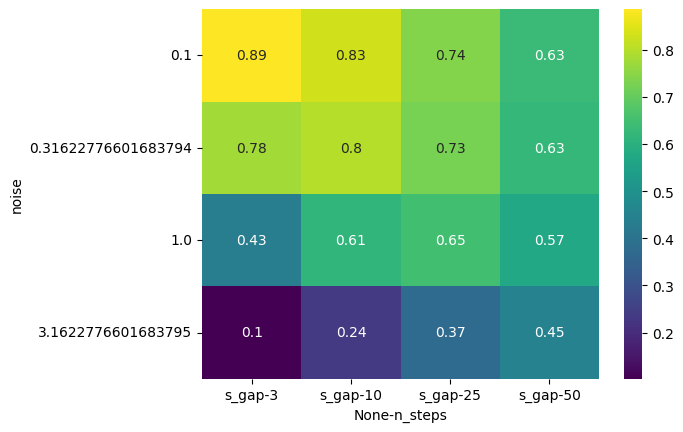

In [151]:
a = data_arrays["s_gap_td"]
sel = a[:, a["rlen"] == 10_000, a["tlen"] == 50, :, a["delay"] == 1]
df = sel.squeeze().astype(float).to_dataframe(name="s_gap").drop(columns=["rlen", "tlen", "delay"]).unstack()
sns.heatmap(df, annot=True, cmap="viridis")

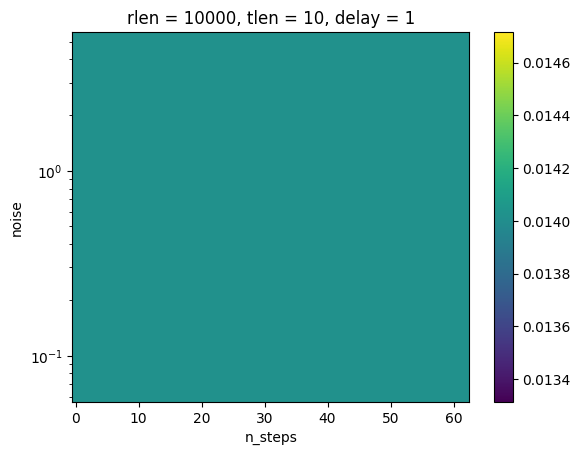

In [35]:
a = data_arrays["s_gap_svd"]
a[:, a["rlen"] == 10_000, a["tlen"] == 10, :, a["delay"] == 1].squeeze().astype(float).plot(yscale="log")

In [16]:
params

OrderedDict([('noise', 0.1),
             ('rlen', 1000),
             ('tlen', 3),
             ('n_steps', 50),
             ('delay', 25)])

In [13]:
data_array_names

['tdsvd', 's_gap_td', 's_gap_svd', 'ncc_td', 'ncc_svd']

In [28]:
"_".join(f"{k}-{v}" for k, v in zip(coords.keys(), params))

'noise-0.1_rlen-1000_tlen-3_n_steps-3_delay-1'

In [24]:
coords.values()

odict_values([array([ 0.1       ,  0.31622777,  1.        ,  3.16227766, 10.        ]), array([ 1000,  5000, 10000, 15000, 30000]), array([ 3,  5,  7, 10, 15, 20, 30, 50]), array([ 3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19,
       20, 21, 22, 23, 24]), array([1, 2, 3, 4, 5, 6, 7, 8, 9])])

In [197]:
noise = 1
rlen = 5_000
tlen = 3
n_steps = 3
delay = 1



tdsvd = TdSVD(
    data=pixels, 
    filename_embedding=f"noise-{noise}-rlen-{rlen}-tlen-{tlen}-n_steps-{n_steps}-delay-{delay}",
    n_time_steps=n_steps,
    delay=delay
)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████| 2/2 [00:00<00:00, 2077.93it/s]


In [198]:
tdsvd.fit(k=3)

In [6]:
%matplotlib ipympl

In [7]:
import seaborn as sns

In [8]:
tdsvd = None

In [9]:
@interact(n_time_steps=(1, 25), delay=(1, 50), k=(2, 10))
def plot_everything(n_time_steps: int = 5, delay: int = 1, k: int = 4):
    fig = plt.figure(figsize=(15, 10))
    grid = plt.GridSpec(10, 10)
    
    toy_plot = fig.add_subplot(grid[0, :])
    sns.heatmap(np.vstack([pixels_clean]), cmap="gnuplot2", ax=toy_plot)
    toy_plot.set_title(f"Toy data of shape: {toy_shape}")
    toy_plot.set_xlabel("Time")
    toy_plot.set_ylabel("pixels")

    toy_plot_noise = fig.add_subplot(grid[1:2, :])
    sns.heatmap(np.vstack([pixels]), cmap="gnuplot2", ax=toy_plot_noise)
    toy_plot_noise.set_title(f"Toy data  + noise: {toy_shape}")
    toy_plot_noise.set_xlabel("Time")
    toy_plot_noise.set_ylabel("pixels")

    global tdsvd
    tdsvd = TdSVD(pixels, n_time_steps=n_time_steps, delay=delay)
    tdsvd.fit(k=k)
    
    plot_embed = fig.add_subplot(grid[2:7, :])
    sns.heatmap(tdsvd.A[:, :200], cmap="gnuplot2", ax=plot_embed)
    plot_embed.set_title(f"Time embedding, shape: {tdsvd.A.shape}, n_steps: {tdsvd.n_time_steps}")
    plot_embed.set_xlabel("Time")
    plot_embed.set_ylabel("pixels over steps")
    
    plot_svals = fig.add_subplot(grid[8:, :3])
    plot_svals.scatter(np.arange(tdsvd.S.size), tdsvd.S / tdsvd.S.max())
    plot_svals.set_yscale("log")
    for x, y in zip(np.arange(tdsvd.S.size), tdsvd.S):
        plot_svals.annotate(f"{y:.2e}", (x + 0.05, y))
    
    plot_svals.set_title(f"Singular values: {np.array2string(tdsvd.S / tdsvd.S.max(), precision=3)}")
    
    plot_u = fig.add_subplot(grid[8:, 3:6])
    img_u = sns.heatmap(tdsvd.U, ax=plot_u, cmap="seismic")
    # fig.colorbar(img_u)
    plot_u.set_title(f"Left singular vectors, shape: {tdsvd.U.shape}")
    
    plot_v = fig.add_subplot(grid[7:, 6:])
    img_v = sns.heatmap(np.vstack([pixels_clean[0, :tdsvd.V.shape[1]] / 10, tdsvd.V]), cmap="seismic", ax=plot_v)
    # fig.colorbar(img_v)
    plot_v.set_title(f"Right singular vectors, shape: {tdsvd.V.shape}")
    
    fig.tight_layout()
    plt.show()

interactive(children=(IntSlider(value=5, description='n_time_steps', max=25, min=1), IntSlider(value=1, descri…

In [199]:
from scipy.linalg import svd

In [55]:
u, s, v = svd(pixels.astype(float))

In [57]:
snorm = s / s.max()
snorm

array([1.        , 0.99327969])

In [58]:
snorm[0] - snorm[1]

0.006720306338879545

In [202]:
tdsvd.S / tdsvd.S.max()

array([1.       , 0.5982902, 0.5777136], dtype=float32)

In [156]:
%matplotlib ipympl

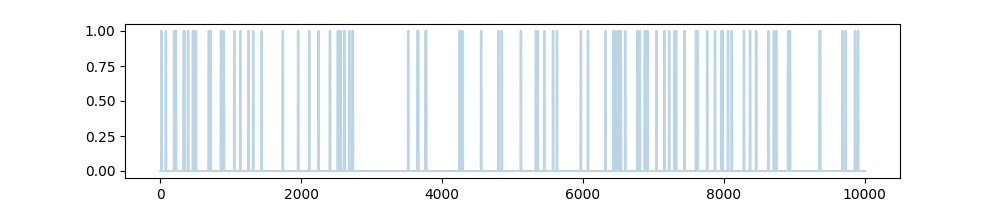

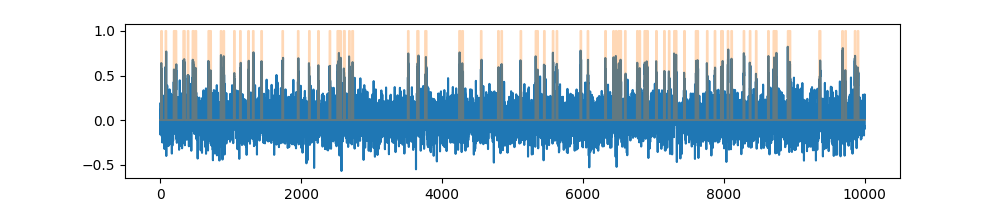

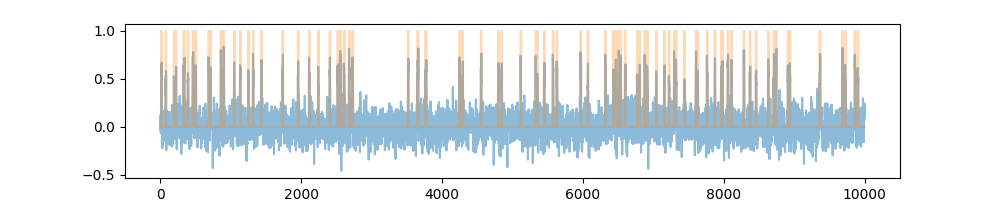

In [204]:
fig = plt.figure(figsize=(10, 2))
plt.plot(pixels_clean.mean(axis=0), alpha=0.3)
plt.show()

# fig = plt.figure(figsize=(10, 2))
# plt.plot(pixels.mean(axis=0))
# # plt.show()

fig = plt.figure(figsize=(10, 2))
plt.plot(-v[0] * 20)
plt.plot(pixels_clean.mean(axis=0), alpha=0.3)
plt.show()

fig = plt.figure(figsize=(10, 2))
plt.plot(-tdsvd.V[0]*20, alpha=0.5)
plt.plot(pixels_clean.mean(axis=0), alpha=0.3)
plt.show()



In [205]:
from tslearn.metrics.cycc import normalized_cc

In [164]:
pixels_clean.shape

(2, 10000)

In [165]:
tdsvd.V.shape

(3, 9997)

In [173]:
tdsvd.V[0].shape

(9997,)

In [174]:
pixels_clean[0, :tdsvd.V.shape[1]].shape

(9997,)

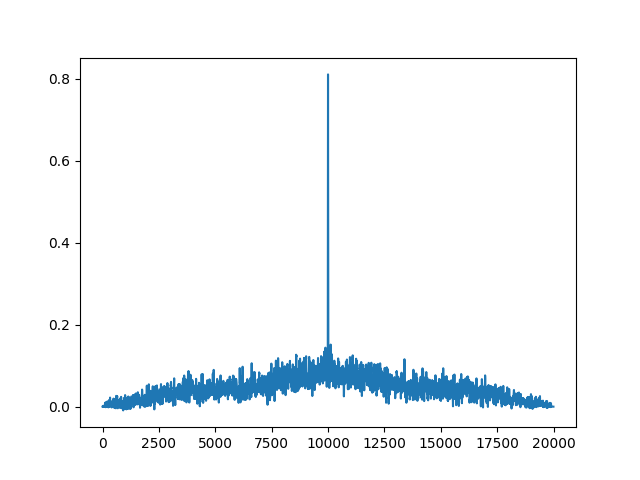

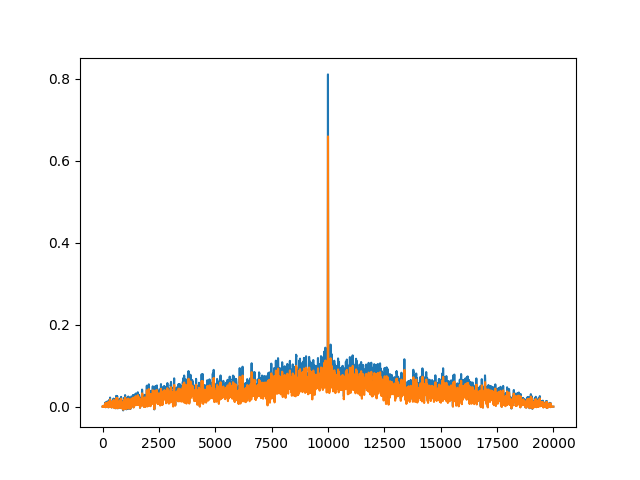

In [207]:
fig = plt.figure()

plt.plot(normalized_cc(pixels_clean[0, :tdsvd.V.shape[1]].reshape(-1, 1), -tdsvd.V[0].reshape(-1, 1)))
plt.show()

plt.plot(normalized_cc(pixels_clean[0].reshape(-1, 1), -v[0].reshape(-1, 1)))
plt.show()

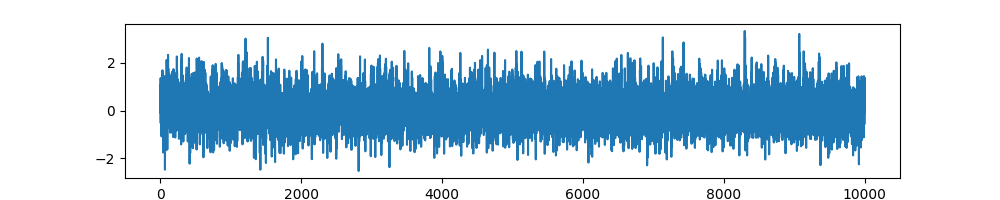

In [15]:
fig = plt.figure(figsize=(10, 2))
plt.plot(pixels.mean(axis=0))
plt.show()

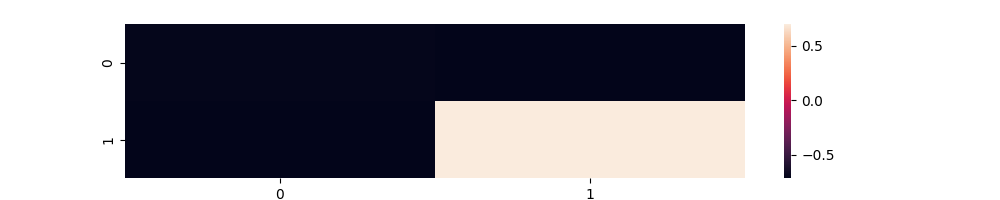

In [15]:
fig = plt.figure(figsize=(10, 2))
sns.heatmap(u)
plt.show()